# Customer Churn Prediction & Retention Strategy
### An End-to-End Machine Learning Project Using Telecom Customer Data

Goal: Build and evaluate a churn-risk model, then consider how a retention team could use its rankings responsibly.
How to run this notebook
1. Open the notebook in Google Colab.
2. Run the first two code cells. When prompted, upload WA_Fn-UseC_-Telco-Customer-Churn.csv.
3. Run the cells from top to bottom. The notebook uses scikit-learn, pandas, NumPy, and Matplotlib.
4. Keep the test set for final evaluation only; do not use it to select or tune the model.

Contents
1. Data loading and quality audit
2. Data cleaning and exploratory analysis
3. Modeling objective, leakage review, and data split
4. Baseline Logistic Regression and validation metrics
5. Model benchmarks and fixed-budget ranking
6. Feature review and model tuning
7. Final test evaluation, calibration, and subgroup diagnostics
8. Retention experiment proposal

Important scope note: The dataset is a historical snapshot and does not define a clear prediction timestamp or future prediction horizon. Treat the results as a modeling exercise, not proof of production-ready future prediction.

In [ ]:
import os
# inspect the Colab working folder
print("Current directory:", os.getcwd())
print("Files here:", os.listdir("/content"))

from google.colab import drive
drive.mount('/content/drive')

Current directory: /content
Files here: ['.config', 'sample_data']
Mounted at /content/drive


In [ ]:
# dataset information
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/your_folder/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)
# Replace your_folder with the folder where you saved the CSV.
print("Dataset shape:", df.shape)
display(df.head())
df.info()

1. DATA QUALITY AUDIT

In [ ]:
# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check missing values
print("\nMissing values by column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Check blank strings in TotalCharges
print("\nBlank TotalCharges:",
      df["TotalCharges"].str.strip().eq("").sum())

# 4. Check the target distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

# 5. Check the target proportions
print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Duplicate rows: 0

Missing values by column:
Series([], dtype: int64)

Blank TotalCharges: 11

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
#inspect the rows with blank TotalCharges

blank_charges = df[
    df["TotalCharges"].str.strip().eq("")
]

display(
    blank_charges[
      ["customerID","tenure","MonthlyCharges",
       "TotalCharges","Churn"]
   ]

)

Note: Data Cleaning Decision -
If all 11 customers have tenure of zero, what might that imply about their billing history?
Should we delete them, replace their blank charges with zero, or use another strategy?
Could deleting these rows introduce bias into our analysis?

In [ ]:
# Work on a copy so the original data remains unchanged
df_clean = df.copy()

# converting blank strings to missing values- so that pandas can identify and count it as missing data
df_clean["TotalCharges"] = (
    df_clean["TotalCharges"].str.strip().replace("", pd.NA)
)

# Convert the column to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="raise"                        #tells pandas to raise an error if it encounters a value that cannot be converted into a number
)

# Fill the verified zero-tenure cases with zero
mask = (
    df_clean["tenure"].eq(0)
    & df_clean["TotalCharges"].isna()
)
df_clean.loc[mask, "TotalCharges"] = 0

# verify the result
print("Data type:",df_clean["TotalCharges"].dtype)
print("Remaining Missing values:",df_clean["TotalCharges"].isna().sum())
print("Zero-tenure customer:", df_clean["tenure"].eq(0).sum())

Data type: float64
Remaining Missing values: 0
Zero-tenure customer: 11


Data-cleaning assumption: blank TotalCharges

The dataset contains 11 blank TotalCharges values. These rows have tenure = 0 and Churn = No. This notebook converts the blanks to missing values, converts the column to numeric, and fills those 11 records with zero. The interpretation is that customers with zero recorded tenure have accumulated zero charges. This is a documented assumption based on the observed rows; in a real project, confirm it with the data owner. The code checks for any other missing TotalCharges values after this step.

Exploratory data analysis (EDA)

In [ ]:
# Are customers on month-to-month contracts more likely to churn than customers on longer contracts?
import pandas as pd

contract_counts = pd.crosstab(         #pd.crosstab() function creates a frequency table that counts how many observations fall into each combination of categories.
    df_clean["Contract"],
    df_clean["Churn"]
)

display(contract_counts)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [ ]:
#churn rate for each contract type:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


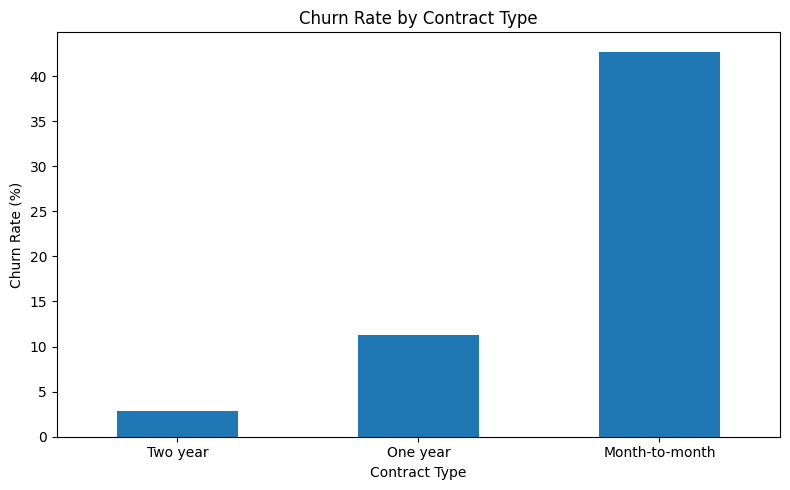

In [ ]:
#visualize the churn rates:
import matplotlib.pyplot as plt

contract_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Finding- Customers on month-to-month contracts are the highest-priority segment for further churn investigation, with a churn
# rate of 42.71%, compared with 2.83% for customers on two-year contracts.The business should investigate what drives churn in
# the month-to-month segment and test whether targeted retention offers improve their retention.

In [ ]:
# Tenure distribution
print(df_clean["tenure"].describe())

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


Understanding the customer lifecycle

In [ ]:
print(df_clean.columns.tolist())# create tenure groups
bins = [0, 6, 12, 24, 48, 60, 72]

labels = [
    "1–6 months",
    "7–12 months",
    "13–24 months",
    "25–48 months",
    "49–60 months",
    "61–72 months"
]

df_clean["tenure_group"] = pd.cut(
    df_clean["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
# Churn rate in each group
tenure_churn = pd.crosstab(
    df_clean["tenure_group"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(tenure_churn.round(2))

Churn,No,Yes
tenure_group,,
1–6 months,47.06,52.94
7–12 months,64.11,35.89
13–24 months,71.29,28.71
25–48 months,79.61,20.39
49–60 months,85.58,14.42
61–72 months,93.39,6.61


Conduct the leakage audit

In [ ]:
print(df_clean.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'tenure_group']


In [ ]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1–6 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25–48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1–6 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25–48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1–6 months


Predict whether a telecom customer will churn using customer, subscription and billing information available at a defined prediction time, so the retention team can prioritize customers for outreach.

Prediction-horizon limitation

The source data does not provide a clear observation date, prediction timestamp, or defined forward-looking horizon (for example, churn within the next 30 or 90 days). Therefore, this project evaluates whether the available customer attributes are associated with the recorded Churn label in this snapshot. A random stratified split supports an internal model comparison, but it does not establish that the model predicts future churn at a defined operational lead time. A production design would need a dated snapshot and a clearly defined outcome window.

Building the modelling dataset and split it

In [ ]:

from sklearn.model_selection import train_test_split

# 1. Separate the target from the input features
X = df_clean.drop(
    columns=["Churn", "customerID", "tenure_group"]
)

y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# 2. Split off 30% for validation and final testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y                                      #Stratification attempts to preserve this class distribution in both the training and temporary sets.
)

# 3. Split that 30% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(

    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 4. Check the results
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nChurn rate in each set:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")


Training set: (4930, 19)
Validation set: (1056, 19)
Test set: (1057, 19)

Churn rate in each set:
Train: 26.53 %
Validation: 26.52 %
Test: 26.58 %


Logistic regression - a baseline

In [ ]:
# LR needs numerical inputs- inspect the data types

# Check the data types of our training features
print("Numerical features:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical features:")
print(X_train.select_dtypes(exclude=["number"]).columns.tolist())


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Creating Preprocessing pipe line

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify the feature groups
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct processing to each group
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Combine preprocessing and the model into one pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


Training Logistic Regression

In [ ]:

# Train the model using training data only
baseline_model.fit(X_train, y_train)

# Predict churn probabilities on the validation set
y_val_proba = baseline_model.predict_proba(X_val)[:, 1]

# Predict classes using the default threshold of 0.5
y_val_pred = baseline_model.predict(X_val)

print("Model training complete!")
print("Validation predictions generated.")


Model training complete!
Validation predictions generated.


Evaluate the validation Predictions

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, y_val_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification report:")
print(classification_report(y_val, y_val_pred, zero_division=0))


Accuracy: 0.806
Precision: 0.646
Recall: 0.593
F1-score: 0.618
ROC-AUC: 0.845

Confusion matrix:
[[685  91]
 [114 166]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       776
           1       0.65      0.59      0.62       280

    accuracy                           0.81      1056
   macro avg       0.75      0.74      0.74      1056
weighted avg       0.80      0.81      0.80      1056



In [ ]:
# the confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val_pred, y_val)
print(cm)

[[685 114]
 [ 91 166]]


In [ ]:
# Testing the prediction
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_val_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_val, y_pred_threshold, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_val, y_pred_threshold, zero_division=0), 3
    ))
    print("F1-score:", round(
        f1_score(y_val, y_pred_threshold, zero_division=0), 3
    ))


Threshold: 0.3
Precision: 0.519
Recall: 0.789
F1-score: 0.626

Threshold: 0.4
Precision: 0.558
Recall: 0.707
F1-score: 0.624

Threshold: 0.5
Precision: 0.646
Recall: 0.593
F1-score: 0.618

Threshold: 0.6
Precision: 0.723
Recall: 0.411
F1-score: 0.524


We will not automatically choose 0.3 just because it has the highest F1-score. The F1-scores are very close across 0.3, 0.4 and 0.5, and F1 doesn't account for business costs.

For project, we'll use 0.3 as a candidate threshold for further evaluation, because catching churners is important. We'll compare it with 0.4 and 0.5 once we define the retention team's capacity and the cost of false alarms.

In [ ]:
# how many customers each threshold actually flags on the validation set.
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_val_proba >= threshold).astype(int)

    print(
        f"Threshold {threshold}: "
        f"{y_pred_threshold.sum()} customers flagged"
    )

Threshold 0.3: 426 customers flagged
Threshold 0.4: 355 customers flagged
Threshold 0.5: 257 customers flagged
Threshold 0.6: 159 customers flagged


In [ ]:
#Select the top 300 highest-risk customers

import numpy as np
from sklearn.metrics import precision_score, recall_score

# Select the 300 customers with the highest churn probabilities
top_n = 300
top_indices = np.argsort(y_val_proba)[::-1][:top_n]

# Mark selected customers as predicted churn = 1
y_top300_pred = np.zeros(len(y_val), dtype=int)
y_top300_pred[top_indices] = 1

# Evaluate the selected group
actual_churners_caught = int(
    ((y_top300_pred == 1) & (y_val.to_numpy() == 1)).sum()
)

print("Customers selected:", int(y_top300_pred.sum()))
print("Actual churners caught:", actual_churners_caught)
print("Precision at top 300:", round(
    precision_score(y_val, y_top300_pred, zero_division=0), 3
))
print("Recall at top 300:", round(
    recall_score(y_val, y_top300_pred, zero_division=0), 3
))


Customers selected: 300
Actual churners caught: 180
Precision at top 300: 0.6
Recall at top 300: 0.643


In [ ]:
#calculate lift directly in Colab so the result is reproducible:
#Retention uplift: Whose behavior can we actually change through an intervention?
baseline_churn_rate = y_val.mean()
top300_precision = precision_score(
    y_val, y_top300_pred, zero_division=0
)

lift_at_300 = top300_precision / baseline_churn_rate

print("Overall churn rate:", round(baseline_churn_rate, 3))
print("Top-300 precision:", round(top300_precision, 3))
print("Lift at 300:", round(lift_at_300, 2))

Overall churn rate: 0.265
Top-300 precision: 0.6
Lift at 300: 2.26


Build a simple model benchmark - Dummy classifier

In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_val)
dummy_proba = dummy_model.predict_proba(X_val)[:, 1]

print("Dummy Classifier — Validation Results")
print("Accuracy:", round(accuracy_score(y_val, dummy_pred), 3))
print("Precision:", round(precision_score(y_val, dummy_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, dummy_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_val, dummy_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, dummy_proba), 3))


Dummy Classifier — Validation Results
Accuracy: 0.735
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5


Trying a tree base model - Random Forest

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_val_pred = rf_model.predict(X_val)
rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest — Validation Results")
print("Accuracy:", round(accuracy_score(y_val, rf_val_pred), 3))
print("Precision:", round(precision_score(y_val, rf_val_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, rf_val_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_val, rf_val_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_proba), 3))
print("PR-AUC:", round(average_precision_score(y_val, rf_val_proba), 3))


Random Forest — Validation Results
Accuracy: 0.768
Precision: 0.545
Recall: 0.754
F1: 0.633
ROC-AUC: 0.841
PR-AUC: 0.625


In [ ]:
# calculating the PR-AUC Of Logistic Regression

from sklearn.metrics import average_precision_score

lr_pr_auc = average_precision_score(y_val, y_val_proba)

print("Logistic Regression PR-AUC:", round(lr_pr_auc, 3))
print("Random Forest PR-AUC:", round(
    average_precision_score(y_val, rf_val_proba), 3
))


Logistic Regression PR-AUC: 0.631
Random Forest PR-AUC: 0.625


The difference is small: \(0.631-0.625=0.006\). We shouldn’t declare Logistic Regression the definitive winner based on this alone

In [ ]:
#Compare both models under the 300-contact limit

import numpy as np
from sklearn.metrics import precision_score, recall_score

def evaluate_top_n(y_true, probabilities, n=300):
    y_array = np.asarray(y_true)
    top_indices = np.argsort(probabilities)[::-1][:n]

    selected = np.zeros(len(y_array), dtype=int)
    selected[top_indices] = 1

    caught = int(((selected == 1) & (y_array == 1)).sum())

    return {
        "Customers contacted": int(selected.sum()),
        "Actual churners caught": caught,
        "Precision@300": round(precision_score(
            y_array, selected, zero_division=0
        ), 3),
        "Recall@300": round(recall_score(
            y_array, selected, zero_division=0
        ), 3),
        "Lift@300": round(
            precision_score(y_array, selected, zero_division=0)
            / y_array.mean(), 2
        )
    }

print("Logistic Regression:", evaluate_top_n(y_val, y_val_proba))
print("Random Forest:", evaluate_top_n(y_val, rf_val_proba))


Logistic Regression: {'Customers contacted': 300, 'Actual churners caught': 180, 'Precision@300': 0.6, 'Recall@300': 0.643, 'Lift@300': np.float64(2.26)}
Random Forest: {'Customers contacted': 300, 'Actual churners caught': 177, 'Precision@300': 0.59, 'Recall@300': 0.632, 'Lift@300': np.float64(2.23)}


provisional decision

I’d carry Logistic Regression forward as the provisional lead model because:
1. It has slightly better ROC-AUC and PR-AUC.
2. It performs slightly better at the fixed 300-contact budget.
3. It is relatively straightforward to explain to business stakeholder

GRADIENT BOOSTING - model check

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# HistGradientBoosting requires numeric inputs,
# so one-hot encode the categorical columns.
gb_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical_features)
])

gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_val_proba = gb_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting — Validation Results")
print("ROC-AUC:", round(roc_auc_score(y_val, gb_val_proba), 3))
print("PR-AUC:", round(average_precision_score(
    y_val, gb_val_proba
), 3))
print("Top-300 results:", evaluate_top_n(y_val, gb_val_proba))


Gradient Boosting — Validation Results
ROC-AUC: 0.841
PR-AUC: 0.638
Top-300 results: {'Customers contacted': 300, 'Actual churners caught': 173, 'Precision@300': 0.577, 'Recall@300': 0.618, 'Lift@300': np.float64(2.17)}


we conclude
- Logistic Regression is currently best for your fixed 300-contact campaign.
- Gradient Boosting has the highest PR-AUC, meaning it has a slight edge on the overall precision–recall trade-off.
- Random Forest achieves the highest recall at the default 0.5 threshold, but that advantage doesn't carry over to the top-300 ranking.

Understand what drives churn predictions
- Positive coefficient: associated with higher predicted churn odds.
- Negative coefficient: associated with lower predicted churn odds.
- Odds ratio above 1: higher odds relative to the model's reference condition.
- Odds ratio below 1: lower odds relative to that reference condition.

In [ ]:

import pandas as pd
import numpy as np

fitted_preprocessor = baseline_model.named_steps["preprocessor"]
fitted_classifier = baseline_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])

print("Top 10 features associated with higher churn odds:")
print(
    coef_df.sort_values("coefficient", ascending=False)
    [["feature", "coefficient", "odds_ratio"]]
    .head(10)
    .round(3)
    .to_string(index=False)
)

print("\nTop 10 features associated with lower churn odds:")
print(
    coef_df.sort_values("coefficient", ascending=True)
    [["feature", "coefficient", "odds_ratio"]]
    .head(10)
    .round(3)
    .to_string(index=False)
)


Top 10 features associated with higher churn odds:
                            feature  coefficient  odds_ratio
                  num__TotalCharges        0.646       1.908
       cat__Contract_Month-to-month        0.585       1.794
   cat__InternetService_Fiber optic        0.493       1.638
cat__PaymentMethod_Electronic check        0.192       1.211
           cat__StreamingMovies_Yes        0.175       1.192
             cat__OnlineSecurity_No        0.162       1.176
                cat__TechSupport_No        0.134       1.143
               cat__StreamingTV_Yes        0.131       1.140
             cat__MultipleLines_Yes        0.085       1.089
                 num__SeniorCitizen        0.052       1.054

Top 10 features associated with lower churn odds:
                                  feature  coefficient  odds_ratio
                              num__tenure       -1.324       0.266
                   cat__Contract_Two year       -0.747       0.474
                 cat__Inte

In [ ]:
#Check whether these findings are stable-how strongly tenure and TotalCharges are correlated in your training data

print("Correlation between tenure and TotalCharges:")
print(round(X_train["tenure"].corr(X_train["TotalCharges"]), 3))

print("\nCorrelation between tenure and MonthlyCharges:")
print(round(X_train["tenure"].corr(X_train["MonthlyCharges"]), 3))

print("\nCorrelation between MonthlyCharges and TotalCharges:")
print(round(X_train["MonthlyCharges"].corr(X_train["TotalCharges"]), 3))


Correlation between tenure and TotalCharges:
0.83

Correlation between tenure and MonthlyCharges:
0.258

Correlation between MonthlyCharges and TotalCharges:
0.654


Remove TotalCharges

In [ ]:

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# Create separate feature sets; preserve the original data.
X_train_no_total = X_train.drop(columns=["TotalCharges"])
X_val_no_total = X_val.drop(columns=["TotalCharges"])

# Rebuild the preprocessing pipeline for the reduced feature set.
numeric_no_total = X_train_no_total.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_no_total = X_train_no_total.select_dtypes(
    exclude=["number"]
).columns.tolist()

preprocessor_no_total = clone(preprocessor)
preprocessor_no_total.set_params(
    transformers=[
        ("num", clone(numeric_transformer), numeric_no_total),
        ("cat", clone(categorical_transformer), categorical_no_total)
    ]
)

lr_no_total = Pipeline([
    ("preprocessor", preprocessor_no_total),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

lr_no_total.fit(X_train_no_total, y_train)
proba_no_total = lr_no_total.predict_proba(X_val_no_total)[:, 1]

print("Original Logistic Regression:")
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 3))
print("PR-AUC:", round(average_precision_score(y_val, y_val_proba), 3))
print("Top-300:", evaluate_top_n(y_val, y_val_proba))

print("\nLogistic Regression without TotalCharges:")
print("ROC-AUC:", round(roc_auc_score(y_val, proba_no_total), 3))
print("PR-AUC:", round(average_precision_score(y_val, proba_no_total), 3))
print("Top-300:", evaluate_top_n(y_val, proba_no_total))


Original Logistic Regression:
ROC-AUC: 0.845
PR-AUC: 0.631
Top-300: {'Customers contacted': 300, 'Actual churners caught': 180, 'Precision@300': 0.6, 'Recall@300': 0.643, 'Lift@300': np.float64(2.26)}

Logistic Regression without TotalCharges:
ROC-AUC: 0.844
PR-AUC: 0.628
Top-300: {'Customers contacted': 300, 'Actual churners caught': 181, 'Precision@300': 0.603, 'Recall@300': 0.646, 'Lift@300': np.float64(2.28)}


In [ ]:
#Tune the model without touching the test set

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_no_total)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train_no_total, y_train)

print("Best C:", grid_search.best_params_["classifier__C"])
print("Best mean CV average precision:",
      round(grid_search.best_score_, 3))


Best C: 0.1
Best mean CV average precision: 0.659


In [ ]:
#Evaluate the tuned model on validation

best_model = grid_search.best_estimator_

tuned_val_proba = best_model.predict_proba(X_val_no_total)[:, 1]

print("Tuned Logistic Regression — Validation Results")
print("ROC-AUC:", round(roc_auc_score(y_val, tuned_val_proba), 3))
print("PR-AUC:", round(
    average_precision_score(y_val, tuned_val_proba), 3
))
print("Top-300:", evaluate_top_n(y_val, tuned_val_proba))


Tuned Logistic Regression — Validation Results
ROC-AUC: 0.843
PR-AUC: 0.629
Top-300: {'Customers contacted': 300, 'Actual churners caught': 179, 'Precision@300': 0.597, 'Recall@300': 0.639, 'Lift@300': np.float64(2.25)}


**Final model choice: reduced, untuned Logistic Regression**

The final test evaluation below intentionally uses *lr_no_total*, the reduced Logistic Regression model without *TotalCharges* and without hyperparameter tuning. On validation, removing *TotalCharges* barely changed performance and slightly improved the fixed-budget ranking (about 181 rather than 180 churners found in the top 300). The tuned version selected *C = 0.1* by cross-validated average precision, but its validation results were not better for the campaign's main top-300 objective (179 churners found, versus 181 for the reduced untuned model). The small differences should not be treated as proof that one model is universally superior; we keep the simpler, untuned reduced model as the documented choice for this project and report its held-out test results once.

For transparency: the tuned model's validation results are reported above, but the final test metrics below are not the tuned model's metrics. The test set remains reserved for the final assessment of the selected *lr_no_total* model.

Lock the model and evaluate the test set

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Evaluate the selected model on the previously untouched test set.
X_test_no_total = X_test.drop(columns=["TotalCharges"])

test_pred = lr_no_total.predict(X_test_no_total)
test_proba = lr_no_total.predict_proba(X_test_no_total)[:, 1]

print("Final Test Results — Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("Precision:", round(precision_score(
    y_test, test_pred, zero_division=0
), 3))
print("Recall:", round(recall_score(
    y_test, test_pred, zero_division=0
), 3))
print("F1:", round(f1_score(y_test, test_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print("PR-AUC:", round(average_precision_score(y_test, test_proba), 3))
print("Top-300:", evaluate_top_n(y_test, test_proba))


Final Test Results — Logistic Regression
Accuracy: 0.8
Precision: 0.664
Recall: 0.505
F1: 0.574
ROC-AUC: 0.843
PR-AUC: 0.652
Top-300: {'Customers contacted': 300, 'Actual churners caught': 180, 'Precision@300': 0.6, 'Recall@300': 0.641, 'Lift@300': np.float64(2.26)}


**The Brier score** :
It measures the average squared difference between predicted probabilities and actual outcomes. Lower is better; zero is perfect.

In [ ]:
# \(p_i\) is the predicted churn probability, and \(y_i\) is 1 if the customer churned and 0 otherwise.

from sklearn.metrics import brier_score_loss

# Use the test probabilities you already calculated.
brier = brier_score_loss(y_test, test_proba)

print("Test Brier score:", round(brier, 4))
print("Test-set churn rate:", round(y_test.mean(), 4))


Test Brier score: 0.137
Test-set churn rate: 0.2658


Draw the reliability diagram- This plot compares what your model predicted with what actually happened in groups of customers.

,Mean predicted probability,Observed churn rate
0,0.036,0.035
1,0.146,0.204
2,0.247,0.239
3,0.342,0.315
4,0.451,0.436
5,0.545,0.595
6,0.646,0.658
7,0.739,0.712
8,0.828,1.000


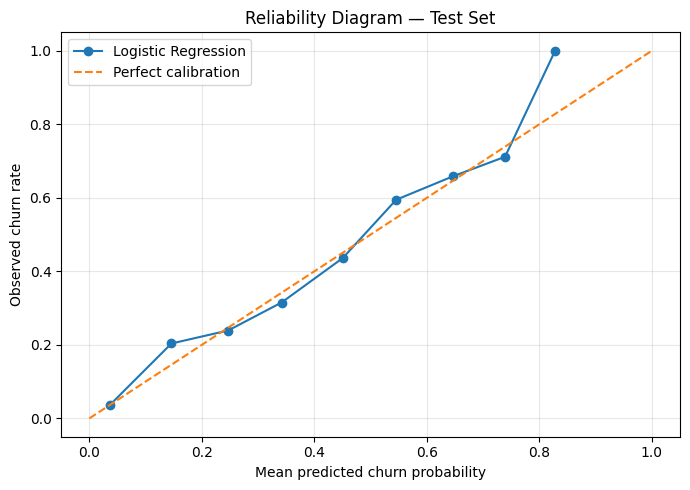

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

observed_rate, mean_predicted = calibration_curve(
    y_test,
    test_proba,
    n_bins=10,
    strategy="uniform"
)

# Print the values behind the chart
calibration_table = pd.DataFrame({
    "Mean predicted probability": mean_predicted,
    "Observed churn rate": observed_rate
})

display(calibration_table.round(3))

# Plot the reliability diagram
plt.figure(figsize=(7, 5))
plt.plot(
    mean_predicted, observed_rate,
    marker="o", label="Logistic Regression"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Perfect calibration"
)

plt.xlabel("Mean predicted churn probability")
plt.ylabel("Observed churn rate")
plt.title("Reliability Diagram — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


fairness check-checking model performance across gender and senior-citizen status

In [ ]:

import pandas as pd
from sklearn.metrics import precision_score, recall_score

fairness_df = pd.DataFrame({
    "gender": X_test["gender"].to_numpy(),
    "SeniorCitizen": X_test["SeniorCitizen"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_pred
})

rows = []

for feature in ["gender", "SeniorCitizen"]:
    for group, data in fairness_df.groupby(feature):
        rows.append({
            "Feature": feature,
            "Group": group,
            "Customers": len(data),
            "Actual churn rate": round(data["actual"].mean(), 3),
            "Predicted positive rate": round(data["predicted"].mean(), 3),
            "Precision": round(precision_score(
                data["actual"], data["predicted"], zero_division=0
            ), 3),
            "Recall": round(recall_score(
                data["actual"], data["predicted"], zero_division=0
            ), 3)
        })

fairness_results = pd.DataFrame(rows)
display(fairness_results)


,Feature,Group,Customers,Actual churn rate,Predicted positive rate,Precision,Recall
0,gender,Female,505,0.291,0.218,0.618,0.463
1,gender,Male,552,0.243,0.188,0.712,0.552
2,SeniorCitizen,0,896,0.234,0.167,0.647,0.462
3,SeniorCitizen,1,161,0.441,0.398,0.703,0.634


In [ ]:
# verifying the fareness table

for feature in ["gender", "SeniorCitizen"]:
    print(f"\n--- {feature} ---")

    for group, data in fairness_df.groupby(feature):
        actual = data["actual"]
        predicted = data["predicted"]

        tp = int(((actual == 1) & (predicted == 1)).sum())
        fp = int(((actual == 0) & (predicted == 1)).sum())
        fn = int(((actual == 1) & (predicted == 0)).sum())

        print(
            f"{group}: n={len(data)}, "
            f"TP={tp}, FP={fp}, FN={fn}, "
            f"churn_rate={actual.mean():.3f}, "
            f"flagged_rate={predicted.mean():.3f}, "
            f"precision={precision_score(actual, predicted, zero_division=0):.3f}, "
            f"recall={recall_score(actual, predicted, zero_division=0):.3f}"
        )



--- gender ---
Female: n=505, TP=68, FP=42, FN=79, churn_rate=0.291, flagged_rate=0.218, precision=0.618, recall=0.463
Male: n=552, TP=74, FP=30, FN=60, churn_rate=0.243, flagged_rate=0.188, precision=0.712, recall=0.552

--- SeniorCitizen ---
0: n=896, TP=97, FP=53, FN=113, churn_rate=0.234, flagged_rate=0.167, precision=0.647, recall=0.462
1: n=161, TP=45, FP=19, FN=26, churn_rate=0.441, flagged_rate=0.398, precision=0.703, recall=0.634


**Design a retention A/B test**

This section is a hypothetical experiment proposal, not a result measured from this dataset. For example, a retention team could randomly assign eligible customers to a treatment (a 10% monthly-plan discount for three months) or business-as-usual control, then compare churn over a defined 90-day follow-up window.

Any sample-size estimate here depends on assumptions such as a 25% control churn rate, a 20% treatment churn rate, 5% significance level, 80% power, and an allowance for attrition. These are planning assumptions, not findings from the Telco dataset. The dataset does not supply a reliable dated follow-up window to estimate the treatment effect. A randomized test is needed to determine whether the offer actually reduces churn; a high-risk prediction alone does not show that an intervention will change a customer's behavior.